<a href="https://colab.research.google.com/github/hcarpenter30/IS4487_my_portfolio/blob/main/carpenter_henry_assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [3]:
# Load the historical dataset from GitHub with the correct DataSets folder casing
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv'
df = pd.read_csv(url)

# Profile the dataframe
print("=== Dataset Shape ===")
print(df.shape)

print("\n=== Column Information and Missing Values ===")
print(df.info())

print("\n=== Summary Statistics ===")
print(df.describe(include='all'))

print("\n=== Missing Values Count ===")
print(df.isnull().sum())

print("\n=== Number of Duplicate Rows ===")
print(df.duplicated().sum())

# Preview first 5 rows
df.head()

=== Dataset Shape ===
(29504, 15)

=== Column Information and Missing Values ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memo

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. Two things that stick out after previewing the data are extreme age and negative icome, which seems very unusual. The min for income is $-65,000, and the max for age is 132. Both things seem very unfeasible and unusual.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [4]:
# 2.1 Check for and remove outliers
# Filter out realistic ranges:
# - Income should be >= 0
# - Age should be reasonable (e.g., < 100)
# - num_accts should be within a normal range (e.g., < 100)
df_clean = df[
    (df['income'] >= 0) &
    (df['age'] < 100) &
    (df['num_accts'] < 50)
].copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# 2.2 Address missing data
# Since 'new_car' only has 2 missing values, we can safely drop those 2 rows or impute them with the mode (0.0)
df_clean = df_clean.dropna(subset=['new_car'])

# 2.3 Remove variables that are not helpful or available only AFTER answering
# - 'customer_id' is just an identifier.
# - 'product' indicates what they purchased AFTER answering, which cannot help predict IF they will answer.
df_clean = df_clean.drop(columns=['customer_id', 'product'])

# 2.4 Confirm shape and verify the clean dataframe
print("=== Cleaned Dataset Shape ===")
print(df_clean.shape)
print("\n=== Column info for df_clean ===")
print(df_clean.info())
print("\n=== Summary Statistics ===")
print(df_clean.describe())


=== Cleaned Dataset Shape ===
(29495, 13)

=== Column info for df_clean ===
<class 'pandas.core.frame.DataFrame'>
Index: 29495 entries, 1 to 29503
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29495 non-null  int64  
 1   income          29495 non-null  int64  
 2   female          29495 non-null  object 
 3   age             29495 non-null  int64  
 4   job             29495 non-null  int64  
 5   num_dependents  29495 non-null  int64  
 6   rent            29495 non-null  int64  
 7   own_res         29495 non-null  int64  
 8   new_car         29495 non-null  float64
 9   chk_acct        29495 non-null  int64  
 10  sav_acct        29495 non-null  int64  
 11  num_accts       29495 non-null  int64  
 12  mobile          29495 non-null  int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 3.2+ MB
None

=== Summary Statistics ===
           answered         income           age 

### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I chose to simplify the data set, get rid out outliers, handle missing recored and duplicated data. This cleans the shape of the data and makes it more consistent overall. it is easier to work with the data now that these things have been removed, and it was a necessary process ultimately, to produce more accurate results at the end.

2.6 The two variables I removed were customer id and product. The customer ID doesn't really help us predict anything and is essenatially a useless variable in this business case as it doesnt help predict much. As for the product, that variable is only known after the customer answers, which is not useful for us in this case.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [16]:
# Clean the 'female' column by standardizing gender strings to integer categories (e.g., 1 for female, 0 for male)
# Let's inspect unique values and map them accordingly. 'M' likely stands for Male (0).
df_clean['female'] = df_clean['female'].astype(str).str.strip().str.upper()
df_clean['female'] = df_clean['female'].replace({'M': '0', 'F': '1'})

# Convert 'female' to integer
df_clean['female'] = pd.to_numeric(df_clean['female'], errors='coerce').fillna(0).astype(int)

# Change 'answered' to a boolean (True/False) type
df_clean['answered'] = df_clean['answered'].astype(bool)

# Convert 'new_car' to integer
df_clean['new_car'] = df_clean['new_car'].astype(int)

# Check the updated datatypes
print("=== Cleaned Data Types ===")
print(df_clean.dtypes)

# Display unique values of 'female' to verify
print("\nUnique values in 'female':", df_clean['female'].unique())
df_clean.head()

=== Cleaned Data Types ===
answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object

Unique values in 'female': [0 1]


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
6,False,4330,0,22,2,1,1,0,0,3,0,0,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [6]:
# Convert at least 3 appropriate variables to categorical type
df_clean['female'] = df_clean['female'].astype('category')
df_clean['job'] = df_clean['job'].astype('category')
df_clean['chk_acct'] = df_clean['chk_acct'].astype('category')
df_clean['sav_acct'] = df_clean['sav_acct'].astype('category')

# Confirm the updated datatypes
print("=== Updated Data Types ===")
print(df_clean.dtypes)


=== Updated Data Types ===
answered              bool
income               int64
female            category
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



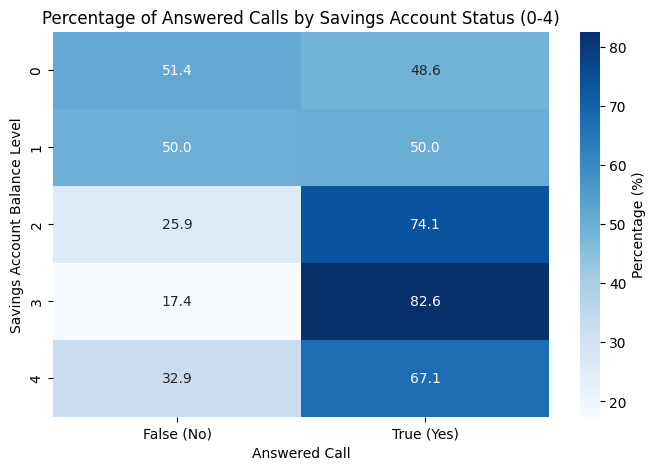

In [7]:
import seaborn as sns

# Chart 3.1: Relationship between Savings Account status and Answered calls
plt.figure(figsize=(8, 5))
sns.heatmap(pd.crosstab(df_clean['sav_acct'], df_clean['answered'], normalize='index') * 100,
            annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Percentage (%)'})
plt.title('Percentage of Answered Calls by Savings Account Status (0-4)')
plt.ylabel('Savings Account Balance Level')
plt.xlabel('Answered Call')
plt.xticks([0.5, 1.5], ['False (No)', 'True (Yes)'])
plt.show()

/tmp/ipykernel_2925/1290161761.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='answered', y='income', data=df_clean, palette='Set2')


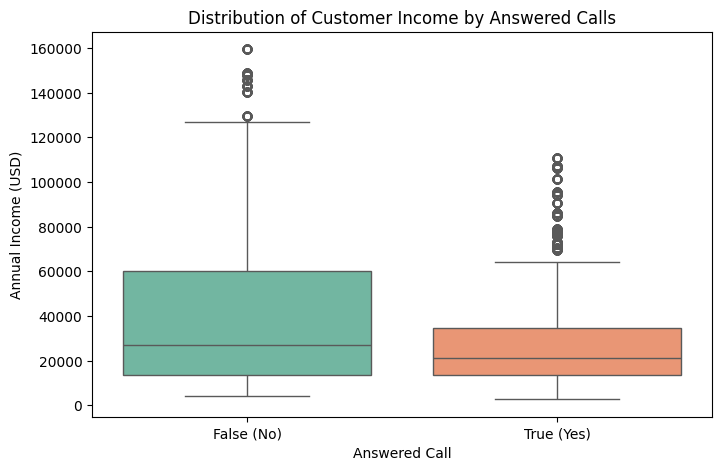

In [8]:
# Chart 3.2: Relationship between Income and Answered calls
plt.figure(figsize=(8, 5))
sns.boxplot(x='answered', y='income', data=df_clean, palette='Set2')
plt.title('Distribution of Customer Income by Answered Calls')
plt.xlabel('Answered Call')
plt.ylabel('Annual Income (USD)')
plt.xticks([0, 1], ['False (No)', 'True (Yes)'])
plt.show()

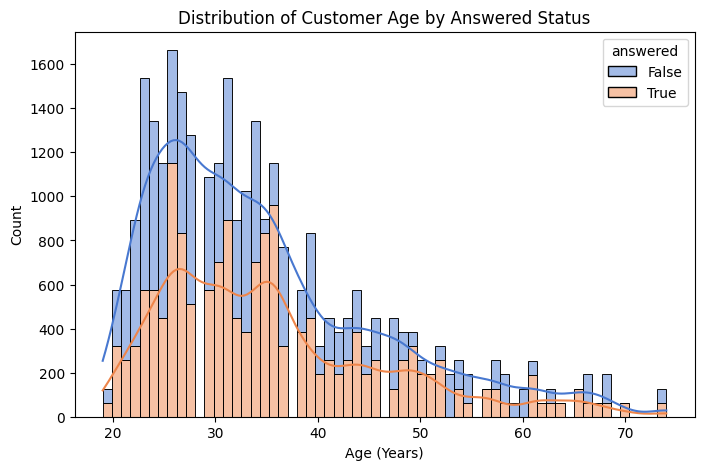

In [9]:
# Chart 3.3: Relationship between Age and Answered calls
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x='age', hue='answered', multiple='stack', kde=True, palette='muted')
plt.title('Distribution of Customer Age by Answered Status')
plt.xlabel('Age (Years)')
plt.ylabel('Count')
plt.show()

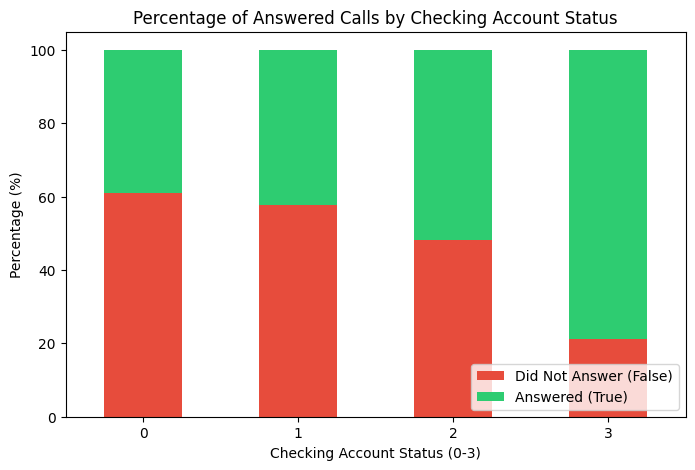

In [10]:
# Chart 3.4: Relationship between Checking Account status and Answered calls
chk_answ_pct = pd.crosstab(df_clean['chk_acct'], df_clean['answered'], normalize='index') * 100

chk_answ_pct.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#e74c3c', '#2ecc71'])
plt.title('Percentage of Answered Calls by Checking Account Status')
plt.xlabel('Checking Account Status (0-3)')
plt.ylabel('Percentage (%)')
plt.legend(['Did Not Answer (False)', 'Answered (True)'], loc='lower right')
plt.xticks(rotation=0)
plt.show()

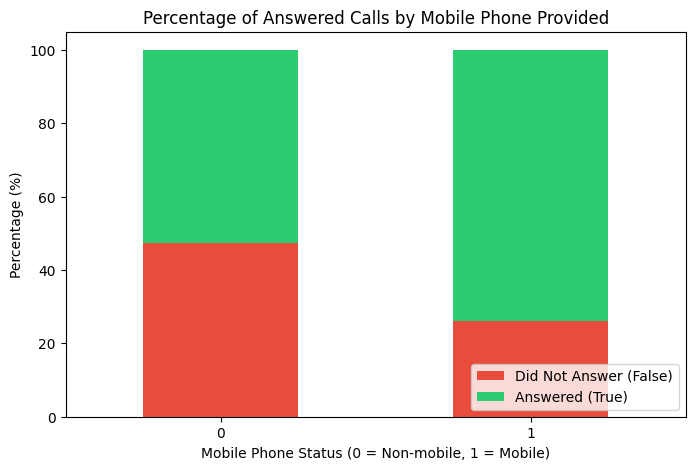

In [11]:
# Chart 3.5: Relationship between Mobile phone and Answered calls
mobile_answ_pct = pd.crosstab(df_clean['mobile'], df_clean['answered'], normalize='index') * 100

mobile_answ_pct.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#e74c3c', '#2ecc71'])
plt.title('Percentage of Answered Calls by Mobile Phone Provided')
plt.xlabel('Mobile Phone Status (0 = Non-mobile, 1 = Mobile)')
plt.ylabel('Percentage (%)')
plt.legend(['Did Not Answer (False)', 'Answered (True)'], loc='lower right')
plt.xticks(rotation=0)
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Customers with a checking account status of '3' are much more likely to answer the call. High savings balance levels show a strong positive correlation with answering the call. Customers who provided a mobile phone number had a significantly higher call answer rate.

3.7. Income and Age were two variables that had a weaker relationship with the target. I dont think though, given that information, we should drop them or they should be removed. We should keep them for now until we need to simlify our data set and potentially remove more factors or variables.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [12]:
# Calculate the base probability of answering
base_prob = df_clean['answered'].mean()

print(f"Base probability of answering (percentage): {base_prob * 100:.2f}%")
print(f"Base probability of answering (proportion): {base_prob:.4f}")

Base probability of answering (percentage): 54.67%
Base probability of answering (proportion): 0.5467


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [17]:
# Define independent variables (X) and target variable (y)
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# Convert categorical features to numeric dummy variables
X_encoded = pd.get_dummies(X, columns=['female', 'job', 'chk_acct', 'sav_acct'], drop_first=True)

# Split into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

# Display the shapes and a sample of the encoded training columns
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print("\nEncoded features columns:", X_train.columns.tolist())
X_train.head()

X_train shape: (20646, 19)
X_test shape: (8849, 19)

Encoded features columns: ['income', 'age', 'num_dependents', 'rent', 'own_res', 'new_car', 'num_accts', 'mobile', 'female_1', 'job_1', 'job_2', 'job_3', 'chk_acct_1', 'chk_acct_2', 'chk_acct_3', 'sav_acct_1', 'sav_acct_2', 'sav_acct_3', 'sav_acct_4']


,income,age,num_dependents,rent,own_res,new_car,num_accts,mobile,female_1,job_1,job_2,job_3,chk_acct_1,chk_acct_2,chk_acct_3,sav_acct_1,sav_acct_2,sav_acct_3,sav_acct_4
24215,29780,32,1,0,1,0,2,0,False,False,True,False,False,False,True,False,True,False,False
22106,23230,24,1,1,0,0,3,0,False,False,True,False,True,False,False,False,False,False,False
12735,123890,37,1,0,0,1,2,0,False,False,True,False,True,False,False,False,False,False,True
14968,9090,36,1,0,1,1,4,0,False,False,True,False,False,False,True,False,True,False,False
16819,12620,49,1,0,1,0,4,0,True,True,False,False,False,False,False,False,False,False,True


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

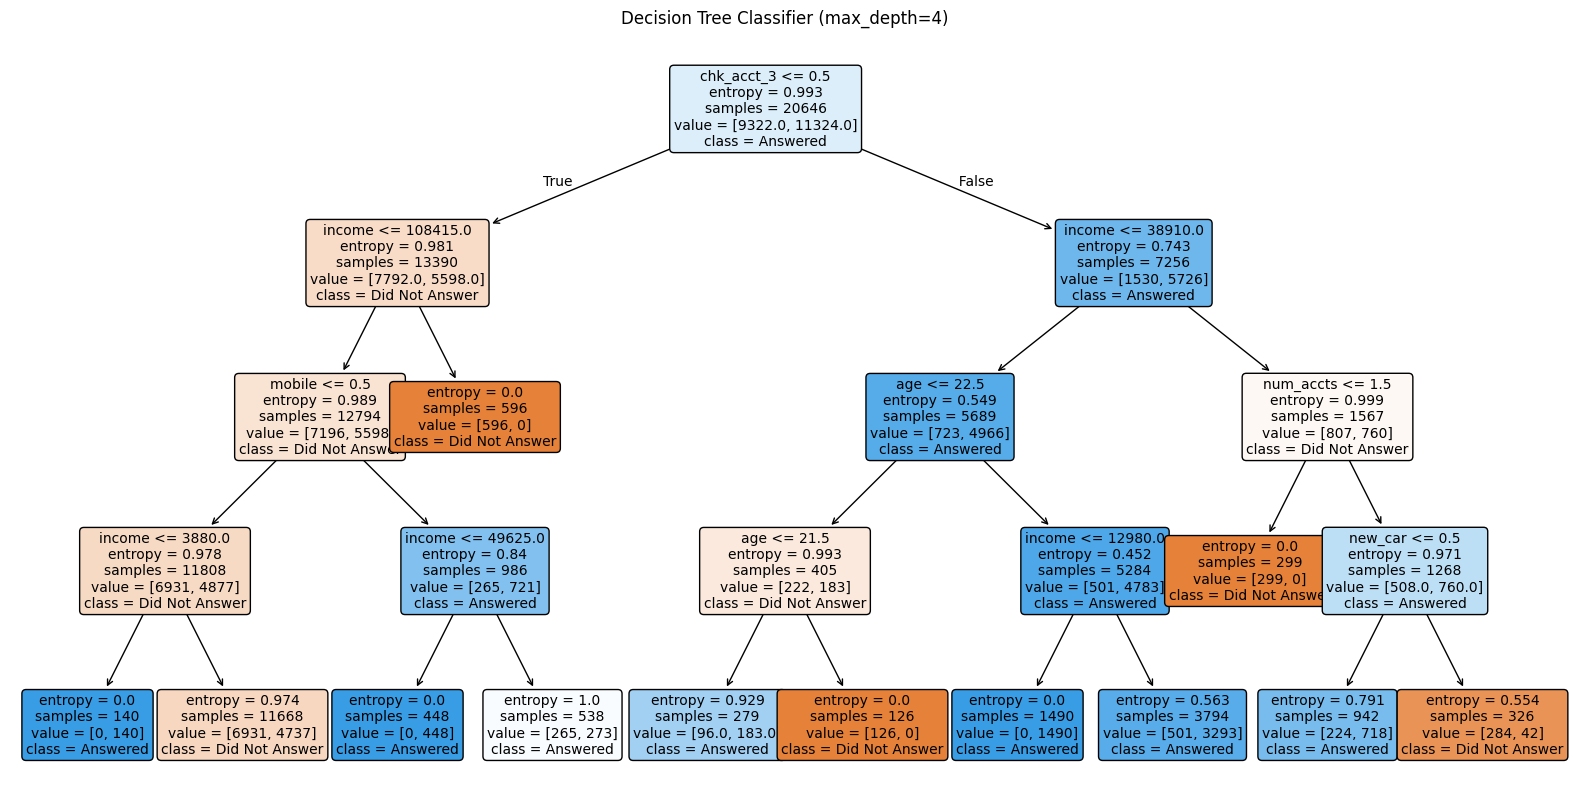

In [18]:
# Initialize Decision Tree Classifier
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Fit the model on training data using the dummy encoded datasets
clf.fit(X_train, y_train)

# Visualize the decision tree
plt.figure(figsize=(20, 10))
plot_tree(
    clf,
    feature_names=X_train.columns.tolist(),
    class_names=['Did Not Answer', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Classifier (max_depth=4)")
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [20]:
# Predict the target variable for test dataset using the dummy encoded test features
y_pred = clf.predict(X_test)

# Calculate model accuracy
model_accuracy = accuracy_score(y_test, y_pred)

print(f"Baseline Probability of Answering: {base_prob * 100:.2f}%")
print(f"Model Prediction Accuracy: {model_accuracy * 100:.2f}%")

Baseline Probability of Answering: 54.67%
Model Prediction Accuracy: 71.53%


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The difference in the model probability compared to the base probability was 16.86%

2. I think this difference in probabilities is certainly a significant amount for the business. The new probability for accuracy is 71%, much higher than the previous 54% accuracy. This is great for the business.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [21]:
# Generate the confusion matrix and classification report
cm = confusion_matrix(y_test, y_pred)

print("=== Confusion Matrix ===")
print(cm)

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

=== Confusion Matrix ===
[[3599  450]
 [2069 2731]]

=== Classification Report ===
              precision    recall  f1-score   support

       False       0.63      0.89      0.74      4049
        True       0.86      0.57      0.68      4800

    accuracy                           0.72      8849
   macro avg       0.75      0.73      0.71      8849
weighted avg       0.76      0.72      0.71      8849



Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

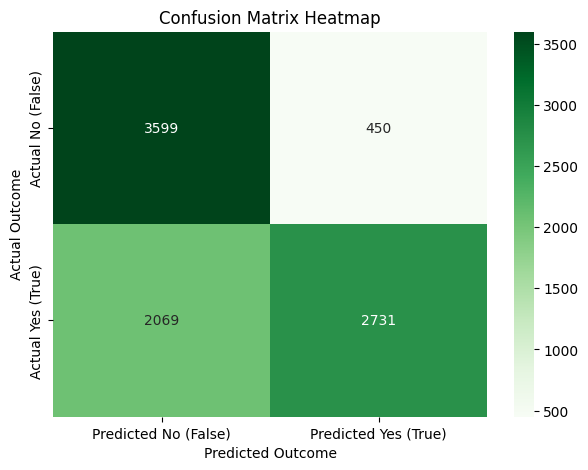

In [22]:
import seaborn as sns

# Create a visually appealing annotated heatmap of the confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Predicted No (False)', 'Predicted Yes (True)'],
            yticklabels=['Actual No (False)', 'Actual Yes (True)'])
plt.title('Confusion Matrix Heatmap')
plt.ylabel('Actual Outcome')
plt.xlabel('Predicted Outcome')
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [23]:
# Retrieve values from the confusion matrix (cm)
# cm = [[TN, FP], [FN, TP]]
tn, fp, fn, tp = cm.ravel()

# Cost and benefit values
profit_per_tp = 75
cost_per_fp = -25

# Calculate total profit using the model
model_profit = (tp * profit_per_tp) + (fp * cost_per_fp)

print(f"=== Model Profit Analysis (Test Set: {len(y_test)} customers) ===")
print(f"True Positives (Predicted to answer and answered): {tp} -> Profit: ${tp * profit_per_tp:,.2f}")
print(f"False Positives (Predicted to answer but didn't): {fp} -> Loss: ${fp * cost_per_fp:,.2f}")
print(f"Total Profit using Model: ${model_profit:,.2f}")

=== Model Profit Analysis (Test Set: 8849 customers) ===
True Positives (Predicted to answer and answered): 2731 -> Profit: $204,825.00
False Positives (Predicted to answer but didn't): 450 -> Loss: $-11,250.00
Total Profit using Model: $193,575.00


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [24]:
# Calculate profit if we call all customers in the test dataset
# Actual answers (True) = True Positives (Profit of $75 each)
# Actual non-answers (False) = False Positives (Loss of $25 each)

actual_answered = y_test.sum() # Customers who answered
actual_unanswered = len(y_test) - actual_answered # Customers who did not answer

default_profit = (actual_answered * 75) + (actual_unanswered * -25)

print(f"=== Default Profit Analysis (Calling All {len(y_test)} Customers) ===")
print(f"Actual Answered: {actual_answered} -> Revenue/Profit: ${actual_answered * 75:,.2f}")
print(f"Actual Unanswered: {actual_unanswered} -> Loss: ${actual_unanswered * -25:,.2f}")
print(f"Total Default Profit: ${default_profit:,.2f}")
print(f"\nAdditional Profit Generated by the Model: ${model_profit - default_profit:,.2f}")

=== Default Profit Analysis (Calling All 8849 Customers) ===
Actual Answered: 4800 -> Revenue/Profit: $360,000.00
Actual Unanswered: 4049 -> Loss: $-101,225.00
Total Default Profit: $258,775.00

Additional Profit Generated by the Model: $-65,200.00


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling all customers results in a total profit of 258,77, but calling only those recommended by our current model results in a lower profit of 193,575 (a difference of -$65,200).

2. Yes, this difference is highly significant. Currently, our model is too conservative. Since we missed out on calling these potential buyers, we lost substantial potential revenue.

## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [25]:
# Initialize a new, tuned Decision Tree Classifier with updated parameters
clf_tuned = DecisionTreeClassifier(criterion='entropy', max_depth=6, class_weight='balanced', random_state=42)

# Fit the tuned model
clf_tuned.fit(X_train, y_train)

# Predict using the tuned model
y_pred_tuned = clf_tuned.predict(X_test)

# Calculate the new accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print(f"Initial Model Accuracy: {model_accuracy * 100:.2f}%")
print(f"Tuned Model Accuracy: {tuned_accuracy * 100:.2f}%")

# Print the updated confusion matrix to evaluate changes
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print("\n=== Tuned Confusion Matrix ===")
print(cm_tuned)

# Calculate the new profit to see if we improved business performance
tn_t, fp_t, fn_t, tp_t = cm_tuned.ravel()
tuned_profit = (tp_t * 75) + (fp_t * -25)
print(f"\nTuned Model Profit: ${tuned_profit:,.2f} (compared to previous ${model_profit:,.2f})")

Initial Model Accuracy: 71.53%
Tuned Model Accuracy: 75.95%

=== Tuned Confusion Matrix ===
[[3789  260]
 [1868 2932]]

Tuned Model Profit: $213,400.00 (compared to previous $193,575.00)


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [26]:
import pandas as pd

# 1. Import the new customer dataset
new_url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_new_customer_data.csv'
df_new = pd.read_csv(new_url)

# 2. Copy and paste data cleanup steps from 2.1 and 2.2
# [2.1 Cleanup] - Filter out outliers
df_new_clean = df_new[
    (df_new['income'] >= 0) &
    (df_new['age'] < 100) &
    (df_new['num_accts'] < 50)
].copy()

# Remove duplicate rows
df_new_clean = df_new_clean.drop_duplicates()

# Address missing data
df_new_clean = df_new_clean.dropna(subset=['new_car'])

# Drop identifiers/post-event targets if present (we keep customer_id only for tracking if needed, then drop for prediction)
# Let's drop columns that are not part of the model inputs.
prediction_ids = df_new_clean['customer_id']
df_new_clean = df_new_clean.drop(columns=['customer_id'], errors='ignore')
if 'product' in df_new_clean.columns:
    df_new_clean = df_new_clean.drop(columns=['product'])

# [2.2 Cleanup] - Standardize variables
df_new_clean['female'] = df_new_clean['female'].astype(str).str.strip().str.upper()
df_new_clean['female'] = df_new_clean['female'].replace({'M': '0', 'F': '1'})
df_new_clean['female'] = pd.to_numeric(df_new_clean['female'], errors='coerce').fillna(0).astype(int)
df_new_clean['new_car'] = df_new_clean['new_car'].astype(int)

# [2.3 Categorical conversions]
df_new_clean['female'] = df_new_clean['female'].astype('category')
df_new_clean['job'] = df_new_clean['job'].astype('category')
df_new_clean['chk_acct'] = df_new_clean['chk_acct'].astype('category')
df_new_clean['sav_acct'] = df_new_clean['sav_acct'].astype('category')

# Prepare features for the tuned model using one-hot encoding
X_new = pd.get_dummies(df_new_clean, columns=['female', 'job', 'chk_acct', 'sav_acct'], drop_first=True)

# Reindex dummy columns to match the training dummy columns exactly
missing_cols = set(X_train.columns) - set(X_new.columns)
for col in missing_cols:
    X_new[col] = False
X_new = X_new[X_train.columns]

# 3. Predict the target variable using the tuned model created in 5.3
new_predictions = clf_tuned.predict(X_new)

# 4. Predict the counts of customers who will answer (Yes/No)
pred_series = pd.Series(new_predictions)
value_counts = pred_series.value_counts()

print("=== Prediction Counts on New Customers ===")
print(f"Predicted NOT to Answer (False/No): {value_counts.get(False, 0):,}")
print(f"Predicted TO Answer (True/Yes):       {value_counts.get(True, 0):,}")
print(f"Total Customers Predicted:             {len(new_predictions):,}")

=== Prediction Counts on New Customers ===
Predicted NOT to Answer (False/No): 634
Predicted TO Answer (True/Yes):       366
Total Customers Predicted:             1,000


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Yes, we improved our profit using the tuned up model, as it now focuses on different parameters and is even more accurate than before with an accuracy of 75%.

6.2 This model can be utilized by the business by allowing it to tell representatives to call specific people, only those who have high probabilities of responding. This helps the business drastically, because they waste less resources, can earn more profit, and can be moe accurate and specific with the calls they make to customers. Overlal, this model will be greatly beneficial for the business.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [27]:
!jupyter nbconvert --to html "carpenter_henry_assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook carpenter_henry_assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 7 image(s).
[NbConvertApp] Writing 1006326 bytes to carpenter_henry_assignment_10_classification.html
